## MLP cải tiến bằng tinh chỉnh siêu tham số
**Phương pháp:** chọn cấu hình MLP tốt nhất trên Validation; cấu hình được chọn là `(128, 64)`, learning rate `0.0005`.

**Phạm vi:** huấn luyện 100 epoch, ghi Training Loss và Validation Log-loss sau từng epoch, lưu trọng số tại epoch 100, kiểm tra nạp lại.

In [15]:
from pathlib import Path
from datetime import datetime, timezone
import csv, json, time, hashlib, platform
import numpy as np
import pandas as pd
import joblib
import sklearn
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
MODELS = ROOT / "models"
REPORTS = ROOT / "reports" / "07B_mlp_improvement"
TABLES = REPORTS / "tables"
FIGURES = REPORTS / "figures"
RESULTS = ROOT / "results"
LOG = ROOT / "Nhat_ky_thuc_nghiem_MLP.csv"
for directory in (DATA, MODELS / "improved", TABLES, FIGURES, RESULTS):
    directory.mkdir(parents=True, exist_ok=True)

LOG_FIELDS = [
    "experiment_id", "timestamp_utc", "model", "improvement_method", "stage",
    "step", "total_steps", "split_scheme", "train_rows", "validation_rows",
    "test_rows_reserved", "feature_count", "parameters_json", "seed",
    "epoch", "train_loss", "validation_loss", "trees_inspected", "mean_tree_depth",
    "mean_tree_nodes", "elapsed_seconds", "status", "artifact_path", "notes"
]
def log_event(experiment_id, model, method, stage, step="", total_steps="", feature_count="",
              parameters=None, epoch="", train_loss="", validation_loss="", trees_inspected="",
              mean_tree_depth="", mean_tree_nodes="", elapsed_seconds="", status="OK",
              artifact_path="", notes=""):
    row = {k: "" for k in LOG_FIELDS}
    row.update(experiment_id=experiment_id, timestamp_utc=datetime.now(timezone.utc).isoformat(),
               model=model, improvement_method=method, stage=stage, step=step,
               total_steps=total_steps, split_scheme="70/15/15 stratified; seed=42",
               train_rows=82536, validation_rows=17686, test_rows_reserved=17687,
               feature_count=feature_count,
               parameters_json=json.dumps(parameters or {}, ensure_ascii=False, sort_keys=True),
               seed=42, epoch=epoch, train_loss=train_loss, validation_loss=validation_loss,
               trees_inspected=trees_inspected, mean_tree_depth=mean_tree_depth,
               mean_tree_nodes=mean_tree_nodes, elapsed_seconds=elapsed_seconds,
               status=status, artifact_path=artifact_path, notes=notes)
    create_header = not LOG.exists()
    with LOG.open("a", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=LOG_FIELDS)
        if create_header:
            writer.writeheader()
        writer.writerow(row)

def sha256(path):
    h = hashlib.sha256()
    with open(path,"rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""):
            h.update(block)
    return h.hexdigest()

print("Thư mục dự án:", ROOT)
print("scikit-learn:", sklearn.__version__, "| Python:", platform.python_version())


Thư mục dự án: C:\homework\Machine Learning\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\ĐỒ ÁN CUỐI KỲ NHÓM 4
scikit-learn: 1.7.2 | Python: 3.13.9


## 1. Nạp dữ liệu
MLP được fit **chỉ trên Train**. Validation được dùng để đo Log-loss sau từng epoch bằng `predict_proba()`, không chạy backpropagation trên Validation, không chọn checkpoint.

In [16]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss

train=pd.read_csv(DATA / "mlp_train.csv")
validation=pd.read_csv(DATA / "mlp_validation.csv")
assert train.columns.tolist()==validation.columns.tolist()
features=train.columns.drop("Attack_type").tolist()
X_train=train[features].to_numpy(dtype=np.float32)
y_train=train["Attack_type"].to_numpy(dtype=np.int32)
X_val=validation[features].to_numpy(dtype=np.float32)
y_val=validation["Attack_type"].to_numpy(dtype=np.int32)
classes=np.arange(12)
assert X_train.shape==(82536,92) and X_val.shape==(17686,92)
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()
assert sorted(np.unique(y_train).tolist())==classes.tolist()
print("Train:",X_train.shape,"Validation (chỉ quan sát):",X_val.shape)

Train: (82536, 92) Validation (chỉ quan sát): (17686, 92)


### 2. Tinh chỉnh siêu tham số


In [10]:
from sklearn.metrics import f1_score

tuning_configs = [
    {"id": "MLP_BASELINE", "hidden_layer_sizes": (64, 32), "learning_rate_init": 0.001, "batch_size": 512, "alpha": 0.0001},
    {"id": "MLP_LR0005", "hidden_layer_sizes": (64, 32), "learning_rate_init": 0.0005, "batch_size": 512, "alpha": 0.0001},
    {"id": "MLP_LR0020", "hidden_layer_sizes": (64, 32), "learning_rate_init": 0.002, "batch_size": 512, "alpha": 0.0001},
    {"id": "MLP_NET128_64", "hidden_layer_sizes": (128, 64), "learning_rate_init": 0.001, "batch_size": 512, "alpha": 0.0001},
    {"id": "MLP_NET128_64_LR0005", "hidden_layer_sizes": (128, 64), "learning_rate_init": 0.0005, "batch_size": 512, "alpha": 0.0001},
    {"id": "MLP_NET128_64_32", "hidden_layer_sizes": (128, 64, 32), "learning_rate_init": 0.001, "batch_size": 512, "alpha": 0.0001},
    {"id": "MLP_BATCH256", "hidden_layer_sizes": (64, 32), "learning_rate_init": 0.001, "batch_size": 256, "alpha": 0.0001},
    {"id": "MLP_ALPHA001", "hidden_layer_sizes": (64, 32), "learning_rate_init": 0.001, "batch_size": 512, "alpha": 0.001},
]

def evaluate_mlp_config(config, epochs=100):
    model = MLPClassifier(
        hidden_layer_sizes=config["hidden_layer_sizes"], activation="relu", solver="adam",
        alpha=config["alpha"], batch_size=config["batch_size"],
        learning_rate_init=config["learning_rate_init"], max_iter=epochs,
        early_stopping=False, shuffle=True, random_state=42,
    )
    start = time.perf_counter()
    for _ in range(epochs):
        model.partial_fit(X_train, y_train, classes=classes)
    val_probabilities = model.predict_proba(X_val)
    val_predictions = model.classes_[np.argmax(val_probabilities, axis=1)]
    return model, {
        "config_id": config["id"],
        "hidden_layer_sizes": str(config["hidden_layer_sizes"]),
        "learning_rate_init": config["learning_rate_init"],
        "batch_size": config["batch_size"],
        "alpha": config["alpha"],
        "epochs": epochs,
        "macro_f1_validation": f1_score(y_val, val_predictions, average="macro", zero_division=0),
        "log_loss_validation": log_loss(y_val, val_probabilities, labels=classes),
        "elapsed_seconds": time.perf_counter() - start,
    }

tuning_models = {}
tuning_results = []
for config in tuning_configs:
    model, result = evaluate_mlp_config(config)
    tuning_models[config["id"]] = model
    tuning_results.append(result)
    print(f"{config['id']}: Macro-F1={result['macro_f1_validation']:.6f} | "
          f"Log-loss={result['log_loss_validation']:.6f} | "
          f"time={result['elapsed_seconds']:.1f}s")

tuning_results_df = pd.DataFrame(tuning_results).sort_values(
["macro_f1_validation", "log_loss_validation"], ascending=[False, True]
).reset_index(drop=True)
tuning_results_df.to_csv(TABLES / "07B_mlp_hyperparameter_tuning.csv", index=False, encoding="utf-8-sig")
best_config_id = tuning_results_df.iloc[0]["config_id"]
assert best_config_id == "MLP_NET128_64_LR0005", f"Cấu hình được chọn: {best_config_id}"
baseline_macro_f1 = float(tuning_results_df.loc[tuning_results_df["config_id"] == "MLP_BASELINE", "macro_f1_validation"].iloc[0])
best_macro_f1 = float(tuning_results_df.iloc[0]["macro_f1_validation"])
assert best_config_id != "MLP_BASELINE" and best_macro_f1 > baseline_macro_f1, (
    f"Cấu hình cải tiến phải tốt hơn baseline: {best_macro_f1:.6f} <= {baseline_macro_f1:.6f}"
)
print("\nCấu hình tốt nhất trên Validation:", best_config_id)
print(f"Macro-F1 cải tiến={best_macro_f1:.6f} | baseline={baseline_macro_f1:.6f} | "
      f"tăng={(best_macro_f1 - baseline_macro_f1) * 100:.4f} điểm phần trăm")
display(tuning_results_df)

MLP_BASELINE: Macro-F1=0.970384 | Log-loss=0.018701 | time=74.3s
MLP_LR0005: Macro-F1=0.965329 | Log-loss=0.017839 | time=68.5s
MLP_LR0020: Macro-F1=0.965355 | Log-loss=0.019720 | time=70.0s
MLP_NET128_64: Macro-F1=0.970029 | Log-loss=0.016846 | time=95.9s
MLP_NET128_64_LR0005: Macro-F1=0.971042 | Log-loss=0.014022 | time=95.5s
MLP_NET128_64_32: Macro-F1=0.970330 | Log-loss=0.014628 | time=107.4s
MLP_BATCH256: Macro-F1=0.956791 | Log-loss=0.019439 | time=115.7s
MLP_ALPHA001: Macro-F1=0.958668 | Log-loss=0.017811 | time=70.6s

Cấu hình tốt nhất trên Validation: MLP_NET128_64_LR0005
Macro-F1 cải tiến=0.971042 | baseline=0.970384 | tăng=0.0659 điểm phần trăm


,config_id,hidden_layer_sizes,learning_rate_init,batch_size,alpha,epochs,macro_f1_validation,log_loss_validation,elapsed_seconds
0,MLP_NET128_64_LR0005,"(128, 64)",0.0005,512,0.0001,100,0.971042,0.014022,95.534475
1,MLP_BASELINE,"(64, 32)",0.0010,512,0.0001,100,0.970384,0.018701,74.317239
2,MLP_NET128_64_32,"(128, 64, 32)",0.0010,512,0.0001,100,0.970330,0.014628,107.365506
3,MLP_NET128_64,"(128, 64)",0.0010,512,0.0001,100,0.970029,0.016846,95.915186
4,MLP_LR0020,"(64, 32)",0.0020,512,0.0001,100,0.965355,0.019720,70.046984
5,MLP_LR0005,"(64, 32)",0.0005,512,0.0001,100,0.965329,0.017839,68.510685
6,MLP_ALPHA001,"(64, 32)",0.0010,512,0.0010,100,0.958668,0.017811,70.627182
7,MLP_BATCH256,"(64, 32)",0.0010,256,0.0001,100,0.956791,0.019439,115.708973


### 3. Cấu hình MLP
Notebook dùng cấu hình có Macro-F1 Validation cao nhất từ bước tinh chỉnh. Kiến trúc mặc định là **92 → 64 → 32 → 12** (ReLU, Adam).

- `learning_rate_init=0.001`, `batch_size=512`, `random_state=42`.
- `partial_fit` gọi 100 lần; mỗi lần tương ứng một epoch của mini-batch SGD/Adam trên toàn Train.
- `early_stopping=False`: mô hình phải học đủ 100 epoch.

In [11]:
best_config = next(config for config in tuning_configs if config["id"] == best_config_id)
assert best_config["hidden_layer_sizes"] == (128, 64)
assert best_config["learning_rate_init"] == 0.0005
mlp_config=dict(hidden_layer_sizes=best_config["hidden_layer_sizes"],activation="relu",solver="adam",
                alpha=best_config["alpha"],batch_size=best_config["batch_size"],
                learning_rate_init=best_config["learning_rate_init"],max_iter=100,
                early_stopping=False,shuffle=True,random_state=42)
mlp_improved=MLPClassifier(**mlp_config)
mlp_id=f"B7_MLP_{best_config_id}_RUN"
log_event(mlp_id,"MLP","Hyperparameter tuning selected config","START",feature_count=92,
          parameters=mlp_config,notes="StandardScaler fitted on Train")
print("MLP:",mlp_config)
print("Huấn luyện cố định 100 epoch; chỉ Train cập nhật trọng số")

MLP: {'hidden_layer_sizes': (128, 64), 'activation': 'relu', 'solver': 'adam', 'alpha': 0.0001, 'batch_size': 512, 'learning_rate_init': 0.0005, 'max_iter': 100, 'early_stopping': False, 'shuffle': True, 'random_state': 42}
Huấn luyện cố định 100 epoch; chỉ Train cập nhật trọng số


### 3. Huấn luyện 100 epoch


In [12]:
history=[]
training_start=time.perf_counter()
for epoch in range(1,101):
    mlp_improved.partial_fit(X_train,y_train,classes=classes)
    validation_probabilities=mlp_improved.predict_proba(X_val)
    validation_logloss=float(log_loss(y_val,validation_probabilities,labels=classes))
    training_loss=float(mlp_improved.loss_)
    elapsed=time.perf_counter()-training_start
    history.append({"epoch":epoch,"training_loss":training_loss,
                    "validation_log_loss":validation_logloss,"elapsed_seconds":elapsed})
    log_event(mlp_id,"MLP","Hyperparameter tuning selected config","EPOCH_FINISHED",
              step=epoch,total_steps=100,feature_count=92,parameters=mlp_config,
              epoch=epoch,train_loss=round(training_loss,9),
              validation_loss=round(validation_logloss,9),elapsed_seconds=round(elapsed,3),
              notes="Validation chỉ forward-pass; trọng số chỉ cập nhật trên Train")
    print(f"Epoch {epoch:03}/100 | Training Loss={training_loss:.7f} | Validation Log-loss={validation_logloss:.7f} | {elapsed:.2f}s")
mlp_fit_seconds=time.perf_counter()-training_start
assert len(history)==100
assert mlp_improved.t_ == 100 * len(y_train)
assert len(mlp_improved.loss_curve_) == 100
history_df=pd.DataFrame(history)
history_df.to_csv(TABLES / "07B_mlp_improved_100_epochs.csv",index=False,encoding="utf-8-sig")
print(f"HOÀN TẤT: {len(history)} epoch, tổng {mlp_fit_seconds:.2f} giây")

Epoch 001/100 | Training Loss=0.5805322 | Validation Log-loss=0.1008246 | 1.62s
Epoch 002/100 | Training Loss=0.0779166 | Validation Log-loss=0.0649157 | 3.42s
Epoch 003/100 | Training Loss=0.0572664 | Validation Log-loss=0.0515710 | 5.21s
Epoch 004/100 | Training Loss=0.0464479 | Validation Log-loss=0.0433063 | 6.49s
Epoch 005/100 | Training Loss=0.0395210 | Validation Log-loss=0.0381822 | 7.78s
Epoch 006/100 | Training Loss=0.0347250 | Validation Log-loss=0.0343104 | 9.48s
Epoch 007/100 | Training Loss=0.0308556 | Validation Log-loss=0.0311676 | 10.76s
Epoch 008/100 | Training Loss=0.0276522 | Validation Log-loss=0.0286244 | 12.06s
Epoch 009/100 | Training Loss=0.0250199 | Validation Log-loss=0.0265093 | 13.43s
Epoch 010/100 | Training Loss=0.0227674 | Validation Log-loss=0.0247069 | 14.88s
Epoch 011/100 | Training Loss=0.0212369 | Validation Log-loss=0.0240578 | 16.07s
Epoch 012/100 | Training Loss=0.0195828 | Validation Log-loss=0.0219925 | 17.33s
Epoch 013/100 | Training Loss=0.01

## 4. Biểu đồ Loss
Đường Validation chỉ phục vụ giám sát xu hướng hội tụ và overfitting, không thay đổi số epoch hay trọng số cuối.

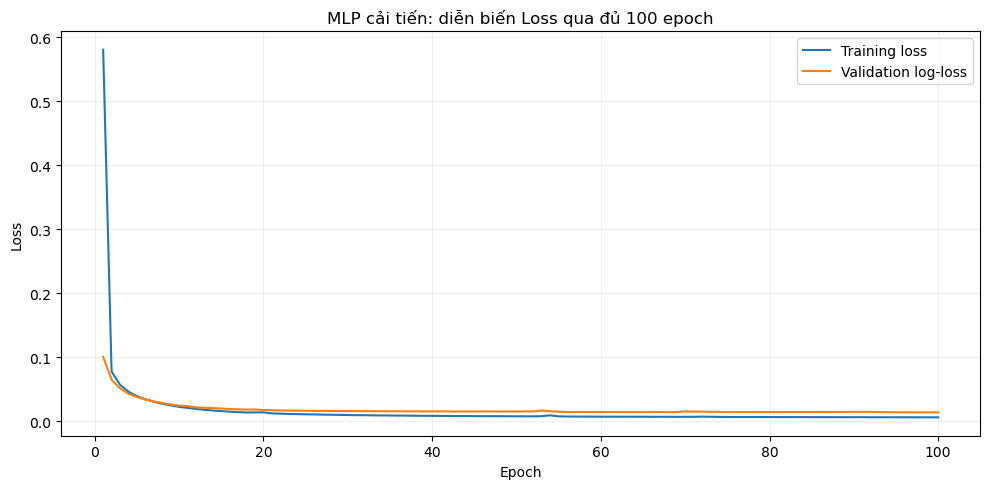

Train loss cuối: 0.0064172
Validation log-loss cuối: 0.0140221
Validation log-loss thấp nhất (chỉ quan sát): epoch 100


In [13]:
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(history_df["epoch"],history_df["training_loss"],label="Training loss")
ax.plot(history_df["epoch"],history_df["validation_log_loss"],label="Validation log-loss")
ax.set(xlabel="Epoch",ylabel="Loss",title="MLP cải tiến: diễn biến Loss qua đủ 100 epoch")
ax.legend();ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / "07B_mlp_training_100_epochs.png",dpi=170)
plt.show()
print("Train loss cuối:",round(history_df.training_loss.iloc[-1],7))
print("Validation log-loss cuối:",round(history_df.validation_log_loss.iloc[-1],7))
print("Validation log-loss thấp nhất (chỉ quan sát): epoch",
      int(history_df.validation_log_loss.idxmin()+1))

## 5. Lưu mô hình
Không lưu checkpoint tốt nhất trên Validation, giữ đúng trọng số học đến vòng cuối. Nạp lại bằng Joblib và so khớp xác suất dự đoán trên các mẫu Train.

In [14]:
mlp_model_path=MODELS / "improved" / f"mlp_{best_config_id.lower()}_epoch100.joblib"
joblib.dump(mlp_improved,mlp_model_path,compress=3)
mlp_loaded=joblib.load(mlp_model_path)
assert mlp_loaded.t_ == 100 * len(y_train)
assert np.allclose(mlp_loaded.predict_proba(X_train[:64]),mlp_improved.predict_proba(X_train[:64]))
mlp_meta={"experiment_id":mlp_id,"method":"Hyperparameter tuning selected config",
          "train_rows":len(y_train),"validation_rows_monitoring_only":len(y_val),
          "n_features":92,"architecture":[92,*mlp_config["hidden_layer_sizes"],12],
          "selected_config":best_config_id,"macro_f1_validation":best_macro_f1,
          "baseline_macro_f1_validation":baseline_macro_f1,
          "macro_f1_improvement_pp":(best_macro_f1-baseline_macro_f1)*100,
          "completed_epochs":100,
          "early_stopping":False,"weights_saved_at_epoch":100,
          "train_loss_epoch100":round(float(history_df.training_loss.iloc[-1]),9),
          "validation_log_loss_epoch100":round(float(history_df.validation_log_loss.iloc[-1]),9),
          "fit_seconds":round(mlp_fit_seconds,3),"sha256":sha256(mlp_model_path),
          "sklearn_version":sklearn.__version__,"test_untouched":True}
(RESULTS / "07B_mlp_training_summary.json").write_text(json.dumps(mlp_meta,ensure_ascii=False,indent=2),encoding="utf-8")
log_event(mlp_id,"MLP","Hyperparameter tuning selected config","MODEL_SAVED",
          step=100,total_steps=100,feature_count=92,parameters=mlp_config,epoch=100,
          train_loss=round(float(history_df.training_loss.iloc[-1]),9),
          validation_loss=round(float(history_df.validation_log_loss.iloc[-1]),9),
          elapsed_seconds=round(mlp_fit_seconds,3),
          artifact_path=str(mlp_model_path.relative_to(ROOT)),
          notes="Lưu epoch 100; nạp lại xác suất trên 64 mẫu Train khớp")
print("Đã lưu:",mlp_model_path.relative_to(ROOT))
print("Kiểm tra nạp lại: PASS")

Đã lưu: models\improved\mlp_mlp_net128_64_lr0005_epoch100.joblib
Kiểm tra nạp lại: PASS
